# Advanced Matplotlib, Part 1: Live-Coding Tutorial · ✍️ STUDENT VERSION

| § | Topic |
|---|-------|
| 0 | Setup + meet the data |
| 1 | Figure and Axes |
| 2 | Reading a plot back |
| 3 | Subplot grids |
| 4 | Bar chart with custom colors |
| 5 | Box plot |
| 6 | Line chart + grid + legend |
| 7 | Heatmap + colorbar |
| 8 | Saving figures |
| 9 | Recap cheat-sheet |

💡 **Tip:** typos are normal. Read the *last line* of an error message first; it usually names the problem.

---
## 0 · Setup + meet the data
We'll use one dataset all session: **a year of daily sales at a small café** (made up, so everyone gets the same numbers). The setup cell is already filled in, so just **run it**.

In [3]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print("matplotlib version:", matplotlib.__version__)

# ── A year of daily sales at a small café (synthetic + reproducible) ──
rng     = np.random.default_rng(42)
dates   = pd.date_range("2025-01-01", "2025-12-31", freq="D")
n       = len(dates)
weekend = dates.dayofweek >= 5

temp   = 15 - 10 * np.cos(2 * np.pi * (dates.dayofyear - 15) / 365) + rng.normal(0, 3, n)
hot    = np.clip(220 - 5 * temp + 40 * weekend + rng.normal(0, 15, n), 0, None).round()
iced   = np.clip(20 + 6 * temp + 30 * weekend + rng.normal(0, 15, n), 0, None).round()
pastry = np.clip(0.4 * (hot + iced) + rng.normal(0, 10, n), 0, None).round()

cafe = pd.DataFrame({
    "date": dates,
    "month": dates.month,
    "day": dates.day_name().str[:3],
    "temp_c": temp.round(1),
    "hot_drinks": hot,
    "iced_drinks": iced,
    "pastries": pastry,
})
cafe["revenue"] = 3.50 * cafe["hot_drinks"] + 4.25 * cafe["iced_drinks"] + 3.00 * cafe["pastries"]

print(cafe.shape)
cafe.head()

matplotlib version: 3.10.8
(365, 8)


,date,month,day,temp_c,hot_drinks,iced_drinks,pastries,revenue
0,2025-01-01,1,Wed,6.2,211.0,64.0,122.0,1376.50
1,2025-01-02,1,Thu,2.1,198.0,34.0,109.0,1164.50
2,2025-01-03,1,Fri,7.5,170.0,73.0,102.0,1211.25
3,2025-01-04,1,Sat,8.0,223.0,95.0,137.0,1595.25
4,2025-01-05,1,Sun,-0.7,276.0,50.0,143.0,1607.50


---
## 1 · Figure and Axes
Every Matplotlib plot is made of **two objects**:

| Object | What it is | Settings that live here |
|---|---|---|
| **Figure** (`fig`) | The whole canvas, like a sheet of paper | size, overall title (`suptitle`), colorbar, saving |
| **Axes** (`ax`) | One plot area drawn on the paper | the data, title, x/y labels, ticks, grid, legend |

One Figure can hold **many** Axes, which is what subplots are.

#### ✍️ Cell [1a]: the quick pyplot style

**🎯 Goal:** Make a line plot the *quick* way, using only `plt.` functions.

**What the code does**
1. `plt.plot(x, y)` draws a line, with dates on the x-axis and temperature on the y-axis.
2. `plt.title(...)` adds a title.
3. `plt.show()` displays the plot.

**✅ You should see:** a wiggly line that rises toward the middle of the year (summer) and falls again.

**💭 Notice:** we never said *which* plot to put the title on. Matplotlib guessed. That works for one plot, but gets confusing with several.

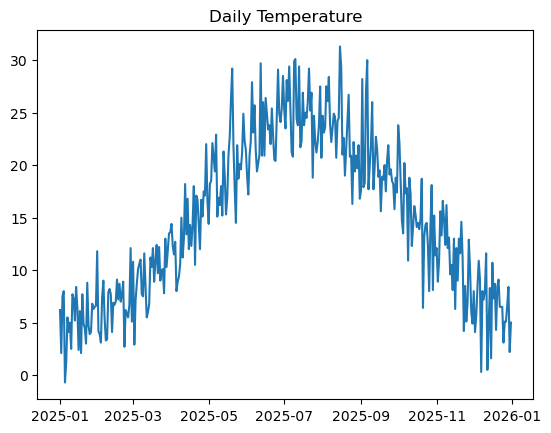

In [11]:
# [1a] the quick pyplot style ✍️ type along

plt.plot(cafe['date'],cafe['temp_c'])
plt.title('Daily Temperature')
plt.show()

#### ✍️ Cell [1b]: the object-oriented style

**🎯 Goal:** Make the **same** plot the *object-oriented* way, the style we'll use for the rest of the course.

**What the code does**
1. `fig, ax = plt.subplots(figsize=(10, 4))` creates **two** objects:
   - `fig` is the **Figure**: the whole canvas (10 inches wide × 4 tall).
   - `ax` is the **Axes**: the single plot area on that canvas.
2. `ax.plot(...)` draws the line **on `ax`**.
3. `ax.set_title(...)` sets the title **of `ax`**. Note the `set_` prefix.
4. `type(fig)` and `type(ax)` print what kind of object each one is.

**✅ You should see:** the same plot as [1a], then two lines of text: one ending in `Figure`, one ending in `Axes`.

**⚠️ Watch out:** it's `ax.set_title("...")`, **not** `ax.title("...")`. The second gives the error `'Text' object is not callable`.

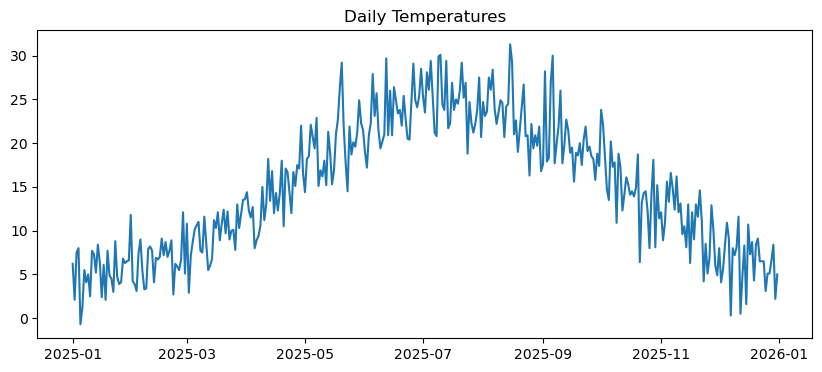

In [10]:
# [1b] the object-oriented style ✍️ type along

fig, ax = plt.subplots(figsize=(10,4))
ax.plot(cafe['date'],cafe['temp_c'])
ax.set_title('Daily Temperatures')
plt.show()

#### ✍️ Cell [1c]: Figure-level vs Axes-level settings

**🎯 Goal:** See which settings belong to the **Figure** and which belong to the **Axes**.

**What the code does**
1. Create `fig, ax` and plot iced drinks per day.
2. Three **Axes-level** settings (they describe one plot): `ax.set_title`, `ax.set_xlabel`, `ax.set_ylabel`.
3. One **Figure-level** setting (it describes the whole canvas): `fig.suptitle`, a "super title" above everything.

**✅ You should see:** **two** titles: "Café 2025" at the very top (the Figure's) and "Iced drinks per day" just above the plot (the Axes').

**💭 Ask yourself before every line:** *does this setting belong to `fig` or to `ax`?* Then check the table below.

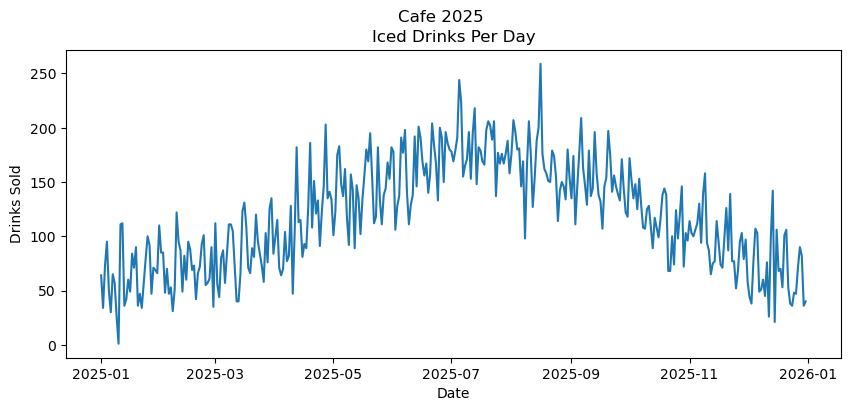

In [15]:
# [1c] Figure-level vs Axes-level settings ✍️ type along

fig, ax = plt.subplots(figsize=(10,4))
ax.plot(cafe['date'],cafe['iced_drinks'])
ax.set_title('Iced Drinks Per Day')
ax.set_xlabel('Date')
ax.set_ylabel('Drinks Sold')
fig.suptitle('Cafe 2025')
plt.show()

**pyplot → object-oriented translation**

| pyplot | Object-oriented |
|---|---|
| `plt.title("...")` | `ax.set_title("...")` |
| `plt.xlabel("...")` / `plt.ylabel(...)` | `ax.set_xlabel("...")` / `ax.set_ylabel(...)` |
| `plt.legend()` | `ax.legend()` |
| `plt.grid()` | `ax.grid()` |

---
## 2 · Reading a plot back
`fig` and `ax` are ordinary Python objects. After you draw, you can **ask them questions**: every `set_...` has a matching `get_...`.

#### ✍️ Cell [2a]: ask the plot about itself

**🎯 Goal:** Draw a plot, then **ask the plot about itself**. Every `set_...` has a matching `get_...`.

**What the code does**
1. Make a revenue plot with a title and a y-label.
2. Read the settings back:
   - `ax.get_title()` / `ax.get_ylabel()` return the text you set.
   - `len(ax.lines)` counts how many lines are drawn on this Axes.
   - `len(fig.axes)` counts how many Axes are on this Figure.
   - `fig.get_size_inches()` returns the figure size.

**✅ You should see:** the printed values (title `Daily revenue`, 1 line, 1 axes, size `[8. 4.]`), then the plot. There's no `plt.show()`, but Jupyter shows the figure at the end of the cell anyway.

**🔗 Why it matters:** this is **exactly how your lab's test cells grade you**, e.g. `assert ax.get_title() == "Tip Distribution"`. A typo in your title means a failed test.

Daily Revenue
Revenue


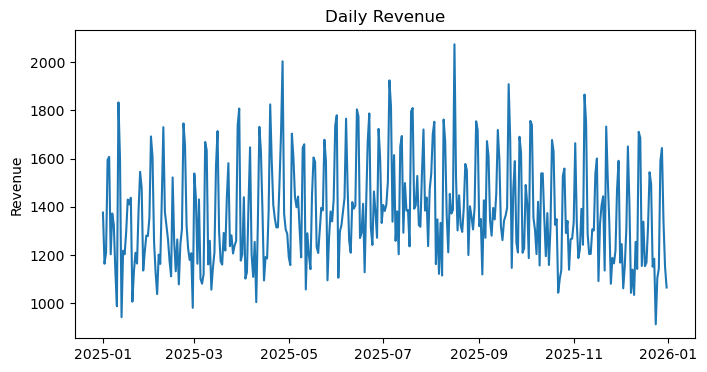

In [17]:
# [2a] ask the plot about itself ✍️ type along

fig, ax = plt.subplots(figsize=(8,4))
ax.plot(cafe['date'],cafe['revenue'])
ax.set_title('Daily Revenue')
ax.set_ylabel('Revenue')
print(ax.get_title())
print(ax.get_ylabel())

#### ✍️ Cell [2b]: change it after drawing

**🎯 Goal:** Change a plot **after** it has been drawn.

**What the code does**
1. `ax.set_title(...)` changes the title of the plot from [2a]. We don't redraw anything.
2. `print(ax.get_title())` confirms the change.
3. A bare `fig` on the last line tells Jupyter to display that figure again.

**✅ You should see:** `Daily revenue, 2025` printed, and the same plot with the new title.

**💭 Takeaway:** `fig` and `ax` are ordinary Python objects that stay around after drawing. You can inspect or change them any time.

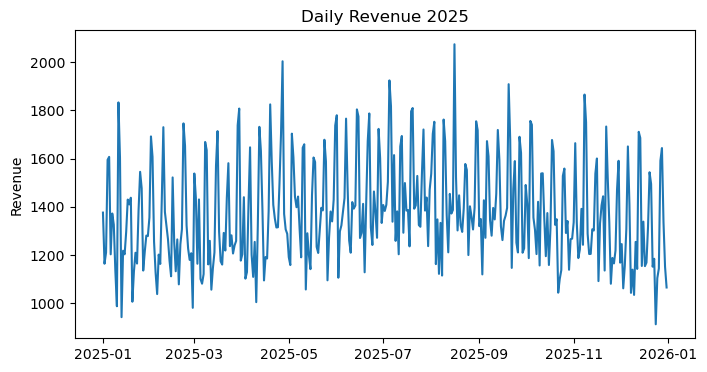

In [18]:
# [2b] change it after drawing ✍️ type along

ax.set_title('Daily Revenue 2025')
fig

---
## 3 · Subplot grids
`plt.subplots(rows, cols)` returns **one Figure** and a **grid (NumPy array) of Axes**. Pick one with `axes[row, col]`, counting from 0:
```
axes[0, 0]   axes[0, 1]
axes[1, 0]   axes[1, 1]
```

#### ✍️ Cell [3a]: a 2×2 grid, one panel at a time

**🎯 Goal:** Put **four plots in a 2 × 2 grid** and fill each panel one at a time.

**What the code does**
1. `monthly = cafe.groupby("month")[[...]].mean()` gives the average of each column for each month (12 rows). Fewer points make small plots easier to read.
2. `fig, axes = plt.subplots(2, 2, ...)` creates one Figure and a **grid of 4 Axes**. Note the plural, `axes`.
3. `axes.shape` prints `(2, 2)`: 2 rows, 2 columns.
4. Select each panel with `axes[row, col]`, counting from **0**, then plot on it and give it a title:

   | | col 0 | col 1 |
   |---|---|---|
   | **row 0** | `axes[0, 0]` Temperature | `axes[0, 1]` Hot drinks |
   | **row 1** | `axes[1, 0]` Iced drinks | `axes[1, 1]` Pastries |
5. `fig.suptitle(...)` adds one title above all four plots.
6. `plt.tight_layout()` adds spacing so titles and labels don't overlap.

**✅ You should see:** four small line plots, each with its own title, and one overall title on top.

**🧪 Try it:** put `#` in front of `plt.tight_layout()` and rerun. See the overlap? Then remove the `#`.

**⚠️ Watch out:** after `groupby("month")`, the month numbers are the **index**, so use `monthly.index`, not `monthly["month"]`.

          temp_c  hot_drinks  iced_drinks    pastries
month                                                
1       5.374194  203.612903    63.161290  109.000000
2       6.464286  197.000000    70.071429  107.035714
3       9.732258  185.677419    86.709677  105.870968
4      14.066667  161.133333   114.400000  110.066667
5      19.793548  129.838710   143.258065  109.322581
6      23.400000  114.233333   164.833333  112.700000
7      24.841935  105.483871   181.580645  111.709677
8      23.106452  115.935484   166.193548  112.483871
9      20.163333  126.566667   150.766667  112.233333
10     14.970968  154.322581   116.387097  108.516129
11     10.786667  177.566667    96.900000  112.933333
12      6.451613  194.258065    65.838710  104.612903


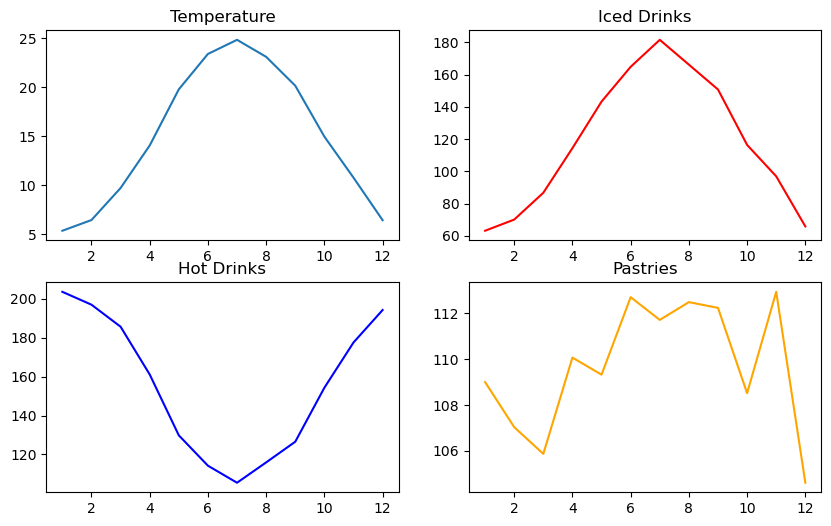

In [25]:
# [3a] a 2×2 grid, one panel at a time ✍️ type along

monthly = cafe.groupby('month')[['temp_c', 'hot_drinks', 'iced_drinks', 'pastries']].mean()
print(monthly)
fig, axes = plt.subplots(2,2,figsize=(10,6))
axes[0,0].plot(monthly.index, monthly['temp_c'])
axes[0,0].set_title('Temperature')
axes[0,1].plot(monthly.index, monthly['iced_drinks'],color='red')
axes[0,1].set_title('Iced Drinks')
axes[1,0].plot(monthly.index, monthly['hot_drinks'],color='blue')
axes[1,0].set_title('Hot Drinks')
axes[1,1].plot(monthly.index, monthly['pastries'],color='orange')
axes[1,1].set_title('Pastries')
plt.show()

#### ✍️ Cell [3b]: the same grid with a loop

**🎯 Goal:** Build the **same** 2 × 2 grid with a **loop** instead of repeating code four times.

**What the code does**
1. Make two lists: the 4 column names and 4 colors.
2. `axes.flat` lets you walk through the grid one panel at a time, in reading order: top-left, top-right, bottom-left, bottom-right.
3. `zip(axes.flat, cols, colors)` pairs them up, so on each pass of the loop you get **one panel (`ax`), one column name, and one color**.
4. Inside the loop: plot that column on that panel with dots (`marker="o"`), then set its title and x-label.
5. Add the overall title and `plt.tight_layout()` as before.

**✅ You should see:** the same four panels as [3a], now with dots on each point and "Month" under each plot.

**⚠️ Watch out:** `axes` (plural) is the whole grid, and `ax` (singular) is the one panel for this loop pass. Mixing them up is the #1 bug here.

In [ ]:
# [3b] the same grid with a loop ✍️ type along



#### ✍️ Cell [3c]: one row → a 1-D list

**🎯 Goal:** See what changes when the grid has **only one row**.

**What the code does**
1. `plt.subplots(1, 3)` makes 1 row × 3 columns.
2. `axes.shape` prints `(3,)`, which is **1-D**: just a list of 3 panels.
3. That means you select a panel with **one** number: `axes[0]`, `axes[1]`, `axes[2]`.

**✅ You should see:** three empty panels titled `axes[0]`, `axes[1]`, `axes[2]`.

**⚠️ Watch out:** `axes[0, 2]` on a single-row grid causes an `IndexError`. One row (or one column) means one index.

**🔗 Lab Part 2** uses a 2 × 3 grid. Bottom-right there is `axes2[1, 2]`.

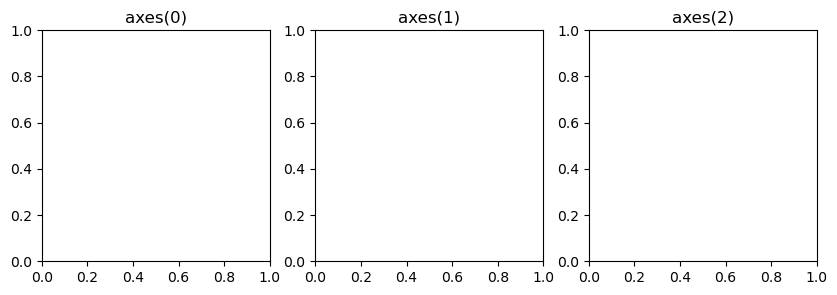

In [26]:
# [3c] one row → a 1-D list ✍️ type along

fig, axes = plt.subplots(1,3,figsize=(10,3))
axes[0].set_title('axes(0)')
axes[1].set_title('axes(1)')
axes[2].set_title('axes(2)')
plt.show()

---
## 4 · Bar chart with custom colors
Recipe: **summarize with `groupby` → put categories in the right order → `ax.bar(categories, values, color=...)`**.

#### ✍️ Cell [4a]: average revenue per weekday

**🎯 Goal:** Compute the **average revenue for each day of the week**, in calendar order.

**What the code does**
1. `order` is a list of the days in the order we want them on the chart.
2. `cafe.groupby("day")["revenue"].mean()` gives the average revenue per day.
3. Print the index (the day names). They come out **alphabetical**: Fri, Mon, Sat, …
4. `.reindex(order)` rearranges the rows into Mon → Sun.

**✅ You should see:** first the alphabetical list, then a table of 7 averages in Mon → Sun order.

**⚠️ Watch out:** if you skip `.reindex(order)`, your bar labels won't match the bar heights, and Python **won't** warn you. Always check the order after a `groupby`.

In [29]:
# [4a] average revenue per weekday ✍️ type along

order = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
avg_rev = cafe.groupby('day')['revenue'].mean()
print(avg_rev)
avg_rev = avg_rev.reindex(order)
print(avg_rev)

day
Fri    1279.432692
Mon    1248.548077
Sat    1662.730769
Sun    1632.543269
Thu    1267.855769
Tue    1283.490385
Wed    1262.948113
Name: revenue, dtype: float64
day
Mon    1248.548077
Tue    1283.490385
Wed    1262.948113
Thu    1267.855769
Fri    1279.432692
Sat    1662.730769
Sun    1632.543269
Name: revenue, dtype: float64


#### ✍️ Cell [4b]: bar chart, weekdays vs weekend colors

**🎯 Goal:** Draw a bar chart where **weekdays are one color and weekends another**.

**What the code does**
1. `colors` is a list with **one color per bar**: 5 gray (Mon–Fri) and 2 orange (Sat–Sun).
2. `ax.bar(order, avg_rev, color=colors, edgecolor="black")` draws the bars. The x-positions are the day names, the heights are the averages, and the fill comes from the color list. `edgecolor` outlines each bar.
3. Add a title and x/y labels, then `plt.tight_layout()`.
4. `len(ax.patches)` counts the bars (Matplotlib calls bars "patches").

**✅ You should see:** 7 bars, with Sat and Sun orange and taller than the others, and `number of bars: 7`.

**🧪 Try it:** delete one `"gray"` from the list and rerun. There's no error, but the colors shift. Then put it back.

**🔗 Lab 3.2** uses the same idea with 4 days and 2 colors.

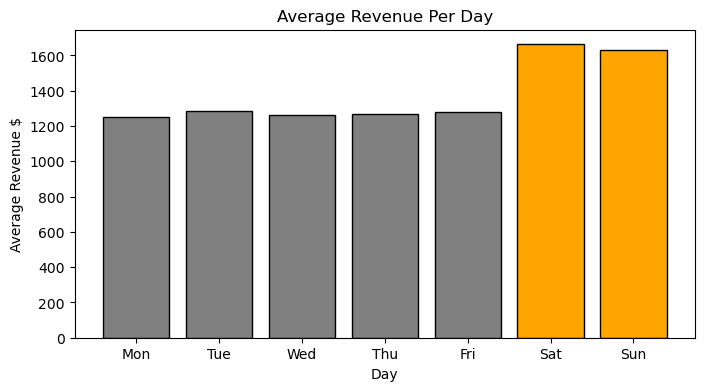

In [32]:
# [4b] bar chart, weekdays vs weekend colors ✍️ type along

colors = ['gray','gray','gray','gray','gray','orange','orange']
fig, ax = plt.subplots(figsize=(8,4))
ax.bar(order,avg_rev,color=colors,edgecolor='black')
ax.set_title('Average Revenue Per Day')
ax.set_xlabel('Day')
ax.set_ylabel('Average Revenue $')
plt.show()

---
## 5 · Box plot
A box plot shows the **spread** of values, not just the average. `ax.boxplot` wants **a list of arrays, one per box**:
```
[ [Mon values...], [Tue values...], ..., [Sun values...] ]
```

#### ✍️ Cell [5a]: build one array per day

**🎯 Goal:** Prepare data for a box plot: a **list containing one array per day**.

`ax.boxplot` needs data shaped like this:
```
[ [Mon revenues...], [Tue revenues...], ..., [Sun revenues...] ]
```

**What the code does**
1. Start with an empty list: `data = []`.
2. Loop over each day `d` in `order`:
   - `cafe[cafe["day"] == d]` keeps only the rows for that day.
   - `["revenue"].values` takes the revenue column as an array.
   - `data.append(values)` adds that array to the list.
3. Print how many arrays we have and peek at Monday's first 5 values.

**✅ You should see:** `7 arrays` and five Monday revenue numbers.

**🔗 Lab 3.1** needs exactly this step: one array of tips per day. Take your time on this cell.

In [36]:
# [5a] build one array per day ✍️ type along

data = []
for d in order:
    values = cafe[cafe['day'] == d]['revenue'].values
    data.append(values)
#print(data)


[array([1203.5 ,  943.  , 1007.  , 1136.25, 1255.5 , 1379.25, 1133.25,
       1323.25, 1164.5 , 1161.75, 1297.75, 1237.5 , 1177.5 , 1202.25,
       1386.75, 1408.25, 1370.75, 1442.5 , 1057.75, 1234.25, 1095.75,
       1106.5 , 1260.75, 1271.25, 1314.75, 1333.5 , 1338.75, 1293.  ,
       1392.5 , 1384.75, 1163.  , 1365.25, 1302.5 , 1200.5 , 1320.25,
       1344.25, 1320.  , 1147.25, 1210.  , 1355.75, 1354.75, 1326.  ,
       1292.  , 1335.  , 1289.  , 1092.5 , 1335.25, 1169.  , 1043.75,
       1155.25, 1152.25, 1337.  ]), array([1372.75, 1218.5 , 1132.75, 1214.25, 1127.5 , 1320.75, 1265.25,
       1227.25, 1431.  , 1259.5 , 1174.75, 1282.25, 1203.75, 1110.  ,
       1095.25, 1352.25, 1306.75, 1398.75, 1290.75, 1209.25, 1272.  ,
       1298.5 , 1210.25, 1292.5 , 1242.25, 1408.  , 1614.75, 1499.  ,
       1406.25, 1439.  , 1348.25, 1211.75, 1448.  , 1402.5 , 1350.  ,
       1280.75, 1262.5 , 1474.5 , 1228.5 , 1305.25, 1195.75, 1349.  ,
       1341.5 , 1188.  , 1204.75, 1331.25, 1081.5 , 1

#### ✍️ Cell [5b]: draw the box plot

**🎯 Goal:** Draw a box plot to see the **spread** of revenue on each day, not just the average.

**What the code does**
1. `ax.boxplot(data, tick_labels=order)` draws one box per array in `data` and labels them with the day names.
2. Add a title and x/y labels, then `plt.tight_layout()`.

**✅ You should see:** 7 boxes, with Sat and Sun sitting higher.

**📖 How to read a box:** the orange line is the **median**, the box covers the **middle 50%** of days, the whiskers show the normal range, and the circles are **unusual days** (outliers).

**⚠️ Watch out:** `tick_labels=` works on Matplotlib **3.9 or newer**. On older versions use `labels=` instead. Check the version printed by the setup cell.

In [ ]:
# [5b] draw the box plot ✍️ type along

fig, ax = plt.subplots()
ax.boxplot(data, tick_labels

> 📝 `boxplot(..., tick_labels=...)` is for Matplotlib ≥ 3.9. Older versions use `labels=`. Check your version in the setup cell output.

---
## 6 · Line chart: markers, grid, legend
Line charts suit data **over time**. Small touches make them easier to read: markers on the points, a light grid, and a legend when there's more than one line.

#### ✍️ Cell [6a]: two lines + legend + grid

**🎯 Goal:** Compare **two lines** on one plot, with a legend and a light grid.

**What the code does**
1. Call `ax.plot(...)` **twice** on the same `ax`, once for hot drinks (red) and once for iced drinks (blue). Each one has:
   - `marker="o"` to put a dot on every month
   - `linewidth=2` for a thicker line
   - `label="..."`, the name shown in the legend
2. Add a title and x/y labels.
3. `ax.grid(True, linestyle="--", alpha=0.5)` adds a dashed grid. `alpha=0.5` makes it half-transparent.
4. `ax.legend()` shows a key built from the `label=` values.

**✅ You should see:** a red line falling into summer and a blue line rising, crossing around May and October, with a legend and a faint dashed grid.

**⚠️ Watch out:** a line without `label=` won't appear in the legend.

**🔗 Lab 3.4** uses the same pieces: `groupby` → `ax.plot(..., marker="o", linewidth=2)` → dashed grid.

In [ ]:
# [6a] two lines + legend + grid ✍️ type along



---
## 7 · Heatmap + colorbar
A **correlation matrix** shows how strongly each pair of columns moves together, from **-1** (opposite) through **0** (unrelated) to **+1** (together). `ax.imshow` draws it as colored squares.

#### ✍️ Cell [7a]: correlation matrix

**🎯 Goal:** Compute a **correlation matrix**, a table showing how strongly each pair of columns moves together.

**What the code does**
1. `cafe.select_dtypes(include="number")` keeps only the numeric columns. You can't correlate text like `"Mon"`.
2. `.drop(columns="month")` removes `month`, which is a label, not a measurement.
3. `.corr()` computes the correlation for every pair of columns. Values run from **-1** (move in opposite directions) through **0** (unrelated) to **+1** (move together).
4. `.round(2)` keeps the table readable.

**✅ You should see:** a square table with `1.00` along the diagonal (each column vs. itself).

**💭 Find:** the most negative number. Why does it make sense?

In [ ]:
# [7a] correlation matrix ✍️ type along



#### ✍️ Cell [7b]: draw it with imshow + colorbar

**🎯 Goal:** Draw the correlation matrix as a **heatmap** with a **colorbar** (a color key).

**What the code does**
1. `labels = corr.columns` holds the column names, for the tick labels.
2. New variable names `fig_corr, ax_corr`: give a figure its own name when you'll need it later (we save it in §8). The lab does the same with `fig_heat`, `fig_ts`, and others.
3. `im = ax_corr.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)`
   - `imshow` draws the table as colored squares.
   - `cmap="coolwarm"` means blue = negative, red = positive.
   - `vmin=-1, vmax=1` fixes the color scale so white means exactly 0.
   - We store the result as `im` because the colorbar needs it.
4. Tick labels take **two steps** per axis:
   - `set_xticks(range(len(labels)))` says *where* the ticks go (0, 1, 2, …).
   - `set_xticklabels(labels, rotation=45, ha="right")` says *what text* goes there. Tilting by 45° stops long names from overlapping.
   - Do the same for y, without rotation.
5. `fig_corr.colorbar(im, ax=ax_corr)` adds the color key. This is a **Figure-level** call.
6. Add a title, then `plt.tight_layout()`.
7. Print how many Axes the figure now has.

**✅ You should see:** a 5 × 5 grid of colored squares with column names on both sides, a color bar on the right, and `axes on this figure: 2`.

**💭 Why 2?** The colorbar is drawn in its **own new Axes**. Lab 3.3's test checks for exactly this.

In [ ]:
# [7b] draw it with imshow + colorbar ✍️ type along



---
## 8 · Saving figures
Call `savefig` **on the figure you want to save**:
- `dpi=` is the resolution (150 is good for slides and reports).
- `bbox_inches="tight"` trims the edges without cutting off rotated labels or the colorbar.

#### ✍️ Cell [8a]: save to a PNG file

**🎯 Goal:** Save the heatmap to an image file.

**What the code does**
1. `fig_corr.savefig("cafe_corr.png", dpi=150, bbox_inches="tight")`
   - It's called **on the figure we want**, `fig_corr`, even though we've drawn other plots since.
   - `dpi=150` is the resolution (dots per inch). Higher means sharper and bigger files.
   - `bbox_inches="tight"` trims the white border without cutting off the tilted labels or the colorbar.
2. `os.path.exists(...)` checks that the file was created, and `os.path.getsize(...)` shows its size.

**✅ You should see:** `True` and a size in KB. Open `cafe_corr.png` from the Jupyter file browser to look at it.

**🔗 Lab 3.5** does the same with `fig_ts`.

In [ ]:
# [8a] save to a PNG file ✍️ type along



---
## 9 · Recap cheat-sheet

| I want to… | Code |
|---|---|
| Start a plot | `fig, ax = plt.subplots(figsize=(w, h))` |
| A grid of plots | `fig, axes = plt.subplots(rows, cols, figsize=(w, h))` |
| Pick one panel | `axes[row, col]` (or `axes[i]` for a single row) |
| Loop over panels | `for ax in axes.flat:` |
| Title and labels | `ax.set_title(...)`, `ax.set_xlabel(...)`, `ax.set_ylabel(...)` |
| Title over the whole figure | `fig.suptitle(...)` |
| Bar chart, one color per bar | `ax.bar(categories, values, color=[...])` |
| Box plot | `ax.boxplot([arr1, arr2, ...], tick_labels=[...])` |
| Line chart | `ax.plot(x, y, marker="o", label="...")`, then `ax.legend()` |
| Dashed grid | `ax.grid(True, linestyle="--", alpha=0.5)` |
| Heatmap + key | `im = ax.imshow(M, cmap="coolwarm", vmin=-1, vmax=1)`, `fig.colorbar(im, ax=ax)` |
| Custom tick labels | `ax.set_xticks(range(n))`, `ax.set_xticklabels(names, rotation=45, ha="right")` |
| Prevent overlap | `plt.tight_layout()` |
| Check a plot | `ax.get_title()`, `len(ax.lines)`, `len(ax.patches)`, `len(fig.axes)` |
| Save | `fig.savefig("name.png", dpi=150, bbox_inches="tight")` |

**Three ideas to remember**
1. **Figure** = the canvas, **Axes** = one plot on it. Ask *"which object owns this setting?"*
2. Create with `fig, ax = plt.subplots(...)`, then talk to `ax` directly.
3. A plot is an object you can inspect. That's how the lab checks your work.

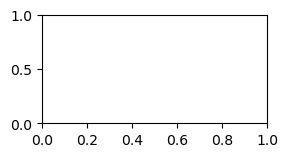

In [5]:
fig_ex = plt.figure()
plot_1 = fig_ex.add_subplot(3, 2, 1)
plt.show()